# Звіт про виконання практичного завдання №3 

## "Дослідження ефективності TF-IDF зважених ембеддингів для детекції текстів, згенерованих великими мовними можелями" 

### з дисципліни "Машинне навчання"

### Виконав:

### студент групи ФеІ-42

### Муртазін Максим

#### Мета роботи: Засвоїти принципи побудови векторних представлень текстів на основі субсловних ембеддингів (Fast Text), дослідити вплив TF-IDF зважування на якість агрегації документних векторів, порівняти ефективність лінійних та нелінійних методів класифікації (SVM, Logistic Regression, KNN) у задачі бінарної детекції штучно згенерованих текстів, а також проаналізувати геометричні властивості отриманих векторних просторів.

#### Хід роботи:

## Налаштування середовища

In [45]:
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from tqdm.auto import tqdm

import spacy
from gensim.models import FastText

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, roc_auc_score,
                             ConfusionMatrixDisplay)
from sklearn.manifold import TSNE

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

In [46]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_PATH       = 'ai_vs_human_text_2026.csv'
MIN_WORDS       = 5 # тексти коротші за стільки слів вважаємо надто короткими
BATCH_SIZE      = 64 # розмір батча для nlp.pipe()
TSNE_PERPLEXITY = 30 # perplexity для t-SNE

LABELS  = {0: 'Human', 1: 'AI'}
PALETTE = {'Human': '#2a7fba', 'AI': '#e0592a'}
MP, TW  = 'Mean Pooling', 'TF-IDF Weighted Mean' # короткі назви методів агрегації

## 1. Теоретичні відомості

### 1.1 Ембеддінги FastText

На відміну від класичного Word2Vec, який будує вектор для цілого слова, FastText розглядає кожне слово як множину символьних $n$-грам. Для слова $w$ довжиною $L$ та фіксованого $n$:

$$G(w)=\{g_i \mid g_i=w[i:i+n],\; i=1,\dots,L-n+1\}\cup\{w\}\tag{1}$$

Вектор слова — сума векторів його $n$-грам:

$$v_w=\sum_{g\in G(w)} z_g\tag{2}$$

Практичні деталі реалізації gensim.models.FastText: слово обрамляється маркерами меж < та >, використовуються $n$-грами довжиною від min_n=3 до max_n=6, а самі $n$-грами хешуються у фіксовану кількість кошиків (bucket=2·10⁶). Параметр sg=1 вмикає архітектуру skip-gram (за центральним словом передбачаються слова контексту у вікні window=5), що краще підходить для рідкісних слів порівняно з CBOW.

Головна перевага — стійкість до слів поза словником (OOV): навіть для слова, якого не було в навчальному корпусі, вектор можна побудувати зі спільних $n$-грам (префікси, суфікси, корені). Для детекції згенерованих текстів це важливо: рідкісні складні слова та морфологічні варіації несуть стилістичну інформацію.

### 1.2 TF-IDF зважування

Статистика TF-IDF для терміна $t$ у документі $d$:

$$\text{TF-IDF}(t,d,D)=\text{tf}(t,d)\cdot \text{idf}(t,D)\tag{3}$$

де $\text{tf}(t,d)$ — частота терміна в документі, а

$$\text{idf}(t,D)=\log\frac{|D|}{|\{d\in D: t\in d\}|}\tag{4}$$

($|D|$ — кількість документів корпусу). Інтуїція: слово, яке трапляється майже в кожному документі («people», «time»), має $\text{idf}\approx 0$ і майже не несе інформації про конкретний документ; рідкісне слово отримує велику вагу.

Примітка про реалізацію. TfidfVectorizer у scikit-learn використовує згладжений варіант $\text{idf}(t)=\ln\frac{1+|D|}{1+\text{df}(t)}+1$. Він збігається з (4) за змістом, але гарантує додатну вагу навіть для слів, що є в усіх документах (інакше сума ваг у (6) могла б дорівнювати нулю). Саме цей варіант використано нижче.

### 1.3 Агрегація документних векторів

Нехай документ $d$ складається з токенів $w_1,\dots,w_m$. Документний вектор отримують двома способами.

Mean Pooling (базовий):
$$v_d^{\text{mean}}=\frac1m\sum_{i=1}^{m}v_{w_i}\tag{5}$$

TF-IDF Weighted Mean (досліджуваний):
$$v_d^{\text{tfidf}}=\frac{\sum_{i=1}^{m}\text{tfidf}(w_i,d,D)\cdot v_{w_i}}{\sum_{i=1}^{m}\text{tfidf}(w_i,d,D)}\tag{6}$$

Обидва вектори є опуклими комбінаціями векторів слів $v_d=\sum_i\alpha_i v_{w_i}$, $\alpha_i\ge0$, $\sum_i\alpha_i=1$; різниця лише у виборі ваг $\alpha_i$. У (5) всі входження мають однакову вагу, тому домінують частотні слова; у (6) вага пропорційна TF-IDF, тобто центр ваги зміщується до рідкісних, специфічних для документа слів.

Технічна особливість формули (6). Сума береться по *всіх входженнях* токенів, а $\text{tf}$ уже враховує кількість входжень, тому слово, яке повторюється $k$ разів, фактично отримує вагу $\propto k^2\cdot\text{idf}$. Реалізація нижче навмисно відтворює саме цю формулу та код із завдання.

### 1.4 Методи класифікації

* SVM з ядром $K(x_i,x_j)$ шукає гіперплощину, що максимізує зазор між класами (у простір ознак, який задає ядро). Функціонал м'якого зазору:
$$\min_{w,b,\xi}\ \frac12\|w\|^2+C\sum_{i=1}^{n}\xi_i\tag{7}$$
У роботі — RBF-ядро $K(x_i,x_j)=\exp(-\gamma\|x_i-x_j\|^2)$, що дозволяє будувати нелінійні межі. Опція probability=True додає калібрування Платта для оцінки ймовірностей (потрібна для ROC-AUC).
* Logistic Regression моделює ймовірність класу через сигмоїду; роздільна межа — лінійна гіперплощина:
$$P(y=1\mid x)=\frac{1}{1+\exp\!\big(-(w^Tx+b)\big)}\tag{8}$$
* KNN відносить об'єкт до класу більшості серед $k$ найближчих сусідів у метричному просторі. Це непараметричний локальний метод: він не навчає ваг ознак і цілком залежить від геометрії простору.

### 1.5 Метрики якості

* **Accuracy** — частка правильних відповідей;
* **Balanced Accuracy** — середнє recall по класах (стійка до дисбалансу);
* **F1 (macro)** — середнє F1 по класах без урахування їх частки;
* **ROC-AUC** — ймовірність того, що випадковий об'єкт класу AI отримає вищий бал, ніж випадковий об'єкт класу Human; не залежить від порога.

## 2. Опис датасету

Використовується датасет AI vs Human Text Classification Dataset 2026 (Kaggle), файл ai_vs_human_text_2026.csv. Він містить тексти двох класів:

* **Human** — тексти, написані людьми;
* **AI** — тексти, згенеровані великими мовними моделями.

Датасет складається з 2000 рядків і 9 колонок: text_id, label, source_model, domain, text_content, topic_hint, word_count, avg_sentence_length, generation_method. Для роботи потрібні дві з них: text_content (текст) та label (клас). Завдання — бінарна класифікація (мітка 1 = AI, 0 = Human).

## 3. Методологія дослідження

### 3.1 Дослідницька гіпотеза

Великі мовні моделі зберігають семантичну відповідність темі (що відбивається у множині вжитих слів), проте залишають статистичні відбитки у використанні специфічної лексики — канцеляризмів, складних сполучників, характерних вставних конструкцій.

**Гіпотеза H₁:** TF-IDF зважування підсилює вплив рідкісних, специфічних для ШІ термінів, що призводить до кращої лінійної роздільності класів порівняно з простим Mean Pooling, де домінують часті загальновживані слова, спільні для обох класів.

### 3.2 Експериментальний план

Факторний аналіз із двома незалежними змінними:

1. Метод агрегації: Mean Pooling vs TF-IDF Weighted Mean;
2. Класифікатор: SVM (RBF), Logistic Regression, KNN.

Разом $2\times3=6$ експериментів на одному й тому самому стратифікованому спліті (80/20), що дає парне порівняння.

Залежні змінні: F1-score (macro), Accuracy, Balanced Accuracy, ROC-AUC.

## Етап 1. Завантаження та первинний аналіз даних

### 1.1 Завантаження датасету

Датасет читається з CSV-файлу. Колонка text_content перейменовується на text, а текстова мітка label перетворюється на число: human → 0, ai → 1.

In [47]:
raw = pd.read_csv(DATA_PATH)

df_raw = pd.DataFrame({'text': raw['text_content'], 'label': raw['label'].map({'human': 0, 'ai': 1})})
df_raw['class'] = df_raw['label'].map(LABELS)

### 1.2 Структура датасету

In [48]:
print('Розмір сирого датасету (рядків, колонок):', raw.shape)
print('\nКолонки та типи даних:')
raw.info()
print('\nПерші рядки:')
display(raw.head())

Розмір сирого датасету (рядків, колонок): (2000, 9)

Колонки та типи даних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   text_id              2000 non-null   object 
 1   label                2000 non-null   object 
 2   source_model         2000 non-null   object 
 3   domain               2000 non-null   object 
 4   text_content         2000 non-null   object 
 5   topic_hint           2000 non-null   object 
 6   word_count           2000 non-null   int64  
 7   avg_sentence_length  2000 non-null   float64
 8   generation_method    2000 non-null   object 
dtypes: float64(1), int64(1), object(7)
memory usage: 140.8+ KB

Перші рядки:


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation


### 1.3 Баланс класів та розподіл довжин текстів

Дисбаланс класів впливає на вибір метрик (звідси Balanced Accuracy та macro-F1), а розподіл довжин показує, чи не відрізняються класи лише довжиною (це був би «ярлик», який класифікатор міг би використати замість стилю).

,Кількість,"Частка, %"
class,,
Human,1334,66.7
AI,666,33.3


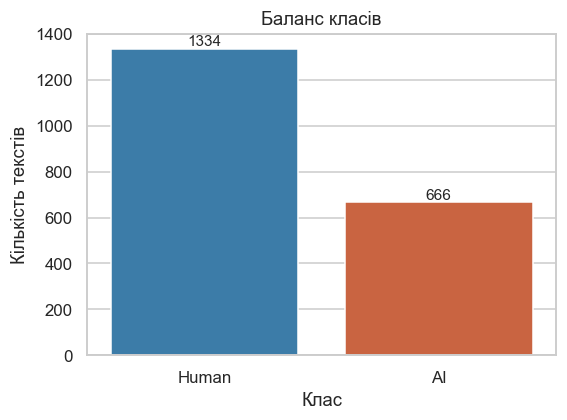

class             AI   Human
n_chars count  666.0  1334.0
        mean   275.6   252.7
        std     71.1    88.3
        min    152.0   123.0
        25%    204.0   153.0
        50%    295.0   253.0
        75%    334.0   330.0
        max    385.0   398.0
n_words count  666.0  1334.0
        mean    38.0    36.5
        std      7.0     9.7
        min     23.0    19.0
        25%     35.0    27.0
        50%     39.0    36.0
        75%     44.0    46.0
        max     50.0    52.0

In [49]:
# Довжини текстів у символах і словах
safe_text = df_raw['text'].fillna('').astype(str)
df_raw['n_chars'] = safe_text.str.len()
df_raw['n_words'] = safe_text.str.split().str.len()

# Баланс класів
counts = df_raw['class'].value_counts(dropna=False)
balance = pd.DataFrame({'Кількість': counts, 'Частка, %': (counts / counts.sum() * 100).round(2)})
display(balance)

fig, ax = plt.subplots(figsize=(5.5, 3.8))
order = [c for c in ['Human', 'AI'] if c in counts.index]
sns.countplot(data=df_raw, x='class', hue='class', order=order, palette=PALETTE, legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=10)
ax.set_title('Баланс класів')
ax.set_xlabel('Клас')
ax.set_ylabel('Кількість текстів')
plt.show()

# Описова статистика довжин
display(df_raw.groupby('class')[['n_chars', 'n_words']].describe().T.round(1))

### 1.4 Виявлення артефактів та гістограми кількості слів

Перевіряємо: порожні/пропущені тексти, дублікати, дублікати з суперечливими мітками (той самий текст позначений обома класами) та надто короткі тексти (менше MIN_WORDS слів).

In [50]:
is_empty = safe_text.str.strip().eq('') # включає NaN та рядки з пробілів
non_empty = ~is_empty
dup_mask = df_raw['text'].duplicated(keep='first') & non_empty # повторні входження того самого тексту

# Тексти, що зустрічаються з різними мітками
nuniq = df_raw[non_empty].groupby('text')['label'].nunique()
conflict_texts = set(nuniq[nuniq > 1].index)
conflict_mask = df_raw['text'].isin(conflict_texts)

short_mask = non_empty & (df_raw['n_words'] < MIN_WORDS)
bad_label = df_raw['label'].isna()

artifacts = pd.DataFrame({
    'Порожні / NaN тексти': is_empty.groupby(df_raw['class']).sum(),
    'Дублікати (повторні входження)': dup_mask.groupby(df_raw['class']).sum(),
    'Тексти з суперечливими мітками': conflict_mask.groupby(df_raw['class']).sum(),
    f'Надто короткі (< {MIN_WORDS} слів)': short_mask.groupby(df_raw['class']).sum(),
}).astype(int)
artifacts.loc['Усього'] = artifacts.sum()
display(artifacts)
print('Рядків без валідної мітки:', int(bad_label.sum()))

,Порожні / NaN тексти,Дублікати (повторні входження),Тексти з суперечливими мітками,Надто короткі (< 5 слів)
class,,,,
AI,0,279,0,0
Human,0,755,0,0
Усього,0,1034,0,0


Рядків без валідної мітки: 0


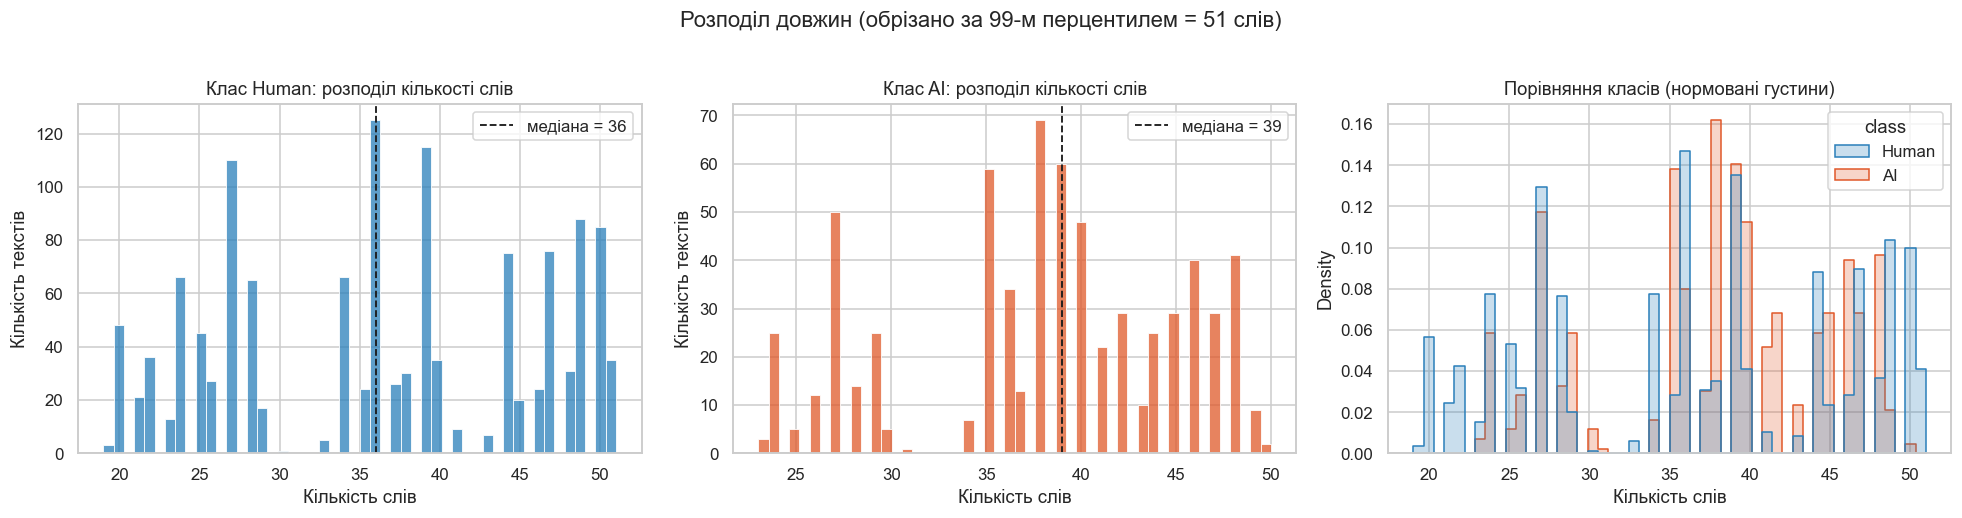

In [51]:
# Гістограми розподілу кількості слів
valid = df_raw[non_empty & ~bad_label]
cap = valid['n_words'].quantile(0.99) # обрізання 1 % найдовших текстів, щоб хвіст не стискав графік

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, cls in zip(axes[:2], ['Human', 'AI']):
    sub = valid.loc[valid['class'] == cls, 'n_words']
    sns.histplot(sub[sub <= cap], bins=50, color=PALETTE[cls], ax=ax)
    ax.axvline(sub.median(), color='k', ls='--', lw=1.2, label=f'медіана = {sub.median():.0f}')
    ax.set_title(f'Клас {cls}: розподіл кількості слів')
    ax.set_xlabel('Кількість слів')
    ax.set_ylabel('Кількість текстів')
    ax.legend()
sns.histplot(data=valid[valid['n_words'] <= cap], x='n_words', hue='class', hue_order=['Human', 'AI'],
             palette=PALETTE, bins=50, stat='density', common_norm=False, element='step', ax=axes[2])
axes[2].set_title('Порівняння класів (нормовані густини)')
axes[2].set_xlabel('Кількість слів')
plt.suptitle(f'Розподіл довжин (обрізано за 99-м перцентилем = {cap:.0f} слів)', y=1.02)
plt.tight_layout()
plt.show()

### 1.5 Очищення даних

Видаляємо виявлені артефакти: порожні тексти та рядки без мітки, тексти з суперечливими мітками (усі копії), точні дублікати (залишаємо перше входження) та надто короткі тексти. Дублікати особливо шкідливі: якщо той самий текст потрапляє і в train, і в test, метрики штучно завищуються (витік даних).

In [52]:
n_before = len(df_raw)

clean = df_raw[non_empty & ~bad_label].copy() # порожні тексти та рядки без мітки
clean = clean[~clean['text'].isin(conflict_texts)] # суперечливі мітки
clean = clean.drop_duplicates(subset='text', keep='first') # точні дублікати
clean = clean[clean['n_words'] >= MIN_WORDS] # надто короткі тексти
clean['label'] = clean['label'].astype(int)

df = clean.reset_index(drop=True)
print(f'Було: {n_before}  ->  після очищення: {len(df)}')
display(df['class'].value_counts().rename('Кількість').to_frame().assign(**{'Частка, %': lambda t: (t['Кількість'] / t['Кількість'].sum() * 100).round(2)}))

Було: 2000  ->  після очищення: 966


,Кількість,"Частка, %"
class,,
Human,579,59.94
AI,387,40.06


### Висновки до Етапу 1

* Датасет містить 2000 текстів і 9 колонок; для роботи використовуються лише text_content та label.
* Класи нерівні: 1334 тексти Human (66,7 %) і 666 текстів AI (33,3 %), тобто співвідношення 2 : 1. Через це поряд з Accuracy обов'язково розглядаємо Balanced Accuracy та macro-F1.
* Тексти дуже короткі: від 19 до 52 слів, медіана — 36 слів для Human і 39 для AI (у середньому 36,5 та 38,0). Класи сильно перекриваються за довжиною: AI-тексти лише трохи довші, тож довжина сама по собі їх не розділяє. Гістограми не гладкі, а стовпчасті — довжини групуються навколо окремих значень, що типово для текстів, створених за шаблонами.
* Порожніх рядків, надто коротких текстів (< 5 слів) та текстів з суперечливими мітками немає. Але 1034 тексти (51,7 %) є точними дублікатами (755 у класі Human, 279 у класі AI). Якби їх залишити, копії одного тексту потрапили б і в навчальну, і в тестову вибірку, а метрики були б завищені. Дублікати видалено.
* Після очищення залишилось 966 унікальних текстів: 579 Human (59,94 %) і 387 AI (40,06 %). Дисбаланс зменшився приблизно до 1,5 : 1.

## Етап 2. Попередня обробка тексту (spaCy)

Пайплайн відповідає наступним вимогам:

1. лематизація — зведення слова до початкової форми (token.lemma_);
2. видалення стоп-слів (token.is_stop);
3. видалення небуквених символів — лишаємо лише токени з token.is_alpha;
4. зведення до нижнього регістру (.lower()).

Функція preprocess — це код із завдання без змін. Для прискорення використовується nlp.pipe() із батчингом (preprocess_corpus), як рекомендовано в завданні; компоненти parser та ner вимкнено, бо для лематизації вони не потрібні.

In [53]:
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])


def preprocess(text: str) -> list:
    doc = nlp(text)
    tokens = []
    for token in doc:
        if token.is_alpha and not token.is_stop:
            tokens.append(token.lemma_.lower())
    return tokens


def preprocess_corpus(texts, batch_size=BATCH_SIZE):
    # Той самий пайплайн, але через nlp.pipe() з батчингом.
    result = []
    for doc in tqdm(nlp.pipe(texts, batch_size=batch_size), total=len(texts), desc='spaCy'):
        result.append([t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop])
    return result


# Приклад роботи пайплайну
example = df['text'].iloc[0]
print('Оригінал (перші 300 символів):\n', example[:300], '\n')
print('Після обробки (перші 40 токенів):\n', preprocess(example)[:40])

Оригінал (перші 300 символів):
 can we talk about gene editing ethics for a sec because i feel like people are completely missing the point here. this is bigger than most realize 

Після обробки (перші 40 токенів):
 ['talk', 'gene', 'edit', 'ethic', 'sec', 'feel', 'like', 'people', 'completely', 'miss', 'point', 'big', 'realize']


In [54]:
t0 = time.time()
df['tokens'] = preprocess_corpus(df['text'].tolist())
print(f'Обробка {len(df)} документів завершена за {time.time() - t0:.1f} с')

df['n_tokens'] = df['tokens'].map(len)
n_empty_tokens = int((df['n_tokens'] == 0).sum())
df = df[df['n_tokens'] > 0].reset_index(drop=True) # прибираємо документи що після обробки стали порожніми
print(f'Документів, що стали порожніми після обробки (видалено): {n_empty_tokens}')
print(f'Лишилось документів: {len(df)}')

spaCy:   0%|          | 0/966 [00:00<?, ?it/s]

Обробка 966 документів завершена за 4.5 с
Документів, що стали порожніми після обробки (видалено): 0
Лишилось документів: 966


### Висновки до Етапу 2

* Пайплайн застосовано до всіх 966 текстів, обробка з nlp.pipe() зайняла близько 4 секунд. Жоден документ не став порожнім після обробки.
* Приклад роботи: розмовний текст про етику редагування генів перетворився на 13 лем (*talk, gene, edit, ethic, sec, feel, like, people, completely, miss, point, big, realize*). Видно лематизацію (*editing → edit*, *ethics → ethic*, *missing → miss*), прибрані стоп-слова (*can, we, about, for, because, i, ...*), розділові знаки та великі літери.
* Побічний ефект: стоп-лист spaCy містить службові слова та сполучники (наприклад, *however*, *moreover*, *therefore*), які іноді вважають стилістичними маркерами тексту ШІ. Після їх видалення ця інформація в подальших векторах відсутня.

## Етап 3. Навчання моделі FastText

Модель навчається бібліотекою gensim на обробленому корпусі (список списків лем) із даними параметрами:

| Параметр | Значення | Зміст |
|---|---|---|
| vector_size | 100 | розмірність вектора слова |
| window | 5 | радіус контекстного вікна |
| min_count | 2 | слова, що трапляються < 2 разів, ігноруються (їхній вектор усе ж можна відновити з $n$-грам) |
| sg | 1 | skip-gram |
| workers | 4 | кількість потоків |
| seed | 42 | початкове значення ГВЧ |

Щодо відтворюваності. Навіть із фіксованим seed багатопотоковий (workers>1) запуск gensim не гарантує побітово однакових векторів між запусками, тому при повторному запуску можливі дрібні розбіжності в значеннях метрик.

Щодо витоку даних. FastText і TF-IDF навчаються на всьому корпусі. Мітки класів при цьому не використовуються (навчання повністю unsupervised), але тестові тексти беруть участь у побудові словника та IDF.

In [55]:
corpus = df['tokens'].tolist() # список документів; кожен документ — список лем
y = df['label'].values.astype(int) # 1 = AI, 0 = Human

t0 = time.time()
ft_model = FastText(
    sentences=corpus,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=4,
    seed=42
)
print(f'FastText навчено за {time.time() - t0:.1f} с')

FastText навчено за 2.5 с


In [56]:
print(f'Розмірність векторів: {ft_model.vector_size}')
print(f'Розмір словника моделі (min_count=2): {len(ft_model.wv)}')

Розмірність векторів: 100
Розмір словника моделі (min_count=2): 508


### Висновки до Етапу 3

* Модель FastText (skip-gram, 100-вимірні вектори) навчена на 966 документах за кілька секунд. Після відсікання за min_count=2 у словнику лишилось лише 508 слів — корпус дуже малий і тематично вузький, тому вектори слів навчаються на обмеженій кількості контекстів.
* Завдяки символьним $n$-грамам модель здатна побудувати вектор і для слова, якого немає у словнику, — це головна перевага FastText над Word2Vec.

## Етап 4. Векторизація документів

Реалізовано два методи агрегації за формулами (5) та (6). Функції mean_pooling та tfidf_weighted_pooling — це код із завдання. Вони приймають список токенів документа, модель FastText і (для другої функції) словник {токен: TF-IDF у цьому документі}.

Деталь поведінки gensim. Для FastText вираз t in model.wv завжди дорівнює True (вектор можна збудувати для будь-якого слова з його $n$-грам), тому умова в if t in model.wv не відкидає токени поза словником — вони представлені $n$-грам-векторами. Нульовий документний вектор тут можливий лише для документа без токенів.

Словники TF-IDF будуються з розрідженої матриці TfidfVectorizer, навченого на оброблених токенах корпусу (norm=None, щоб отримати сирі значення $\text{tf}\cdot\text{idf}$; нормування все одно відбувається всередині функції: weights /= weights.sum()).

In [57]:
def mean_pooling(tokens, model):
    # просте середнє векторів слів документа.
    vectors = [model.wv[t] for t in tokens if t in model.wv]
    if not vectors:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)


def tfidf_weighted_pooling(tokens, model, tfidf_scores):
    # середнє, зважене TF-IDF значеннями токенів у цьому документі.
    vectors, weights = [], []
    for t in tokens:
        if t in model.wv and t in tfidf_scores:
            vectors.append(model.wv[t])
            weights.append(tfidf_scores[t])
    if not vectors:
        return np.zeros(model.vector_size)
    weights = np.array(weights)
    weights /= weights.sum()
    return np.average(vectors, axis=0, weights=weights)

In [58]:
# TF-IDF на корпусі токенів
tfidf_vectorizer = TfidfVectorizer(analyzer=lambda tokens: tokens, norm=None)
tfidf_matrix = tfidf_vectorizer.fit_transform(corpus).tocsr()
feature_names = np.asarray(tfidf_vectorizer.get_feature_names_out())


def doc_tfidf_scores(i):
    # Словник {токен: TF-IDF} для i-го документа
    s, e = tfidf_matrix.indptr[i], tfidf_matrix.indptr[i + 1]
    return dict(zip(feature_names[tfidf_matrix.indices[s:e]].tolist(), tfidf_matrix.data[s:e]))

In [59]:
X_mean  = np.vstack([mean_pooling(toks, ft_model) for toks in tqdm(corpus, desc='Mean Pooling')])
X_tfidf = np.vstack([tfidf_weighted_pooling(toks, ft_model, doc_tfidf_scores(i))
                     for i, toks in enumerate(tqdm(corpus, desc='TF-IDF Weighted Mean'))])
print(f'X_mean: {X_mean.shape},  X_tfidf: {X_tfidf.shape}')

Mean Pooling:   0%|          | 0/966 [00:00<?, ?it/s]

TF-IDF Weighted Mean:   0%|          | 0/966 [00:00<?, ?it/s]

X_mean: (966, 100),  X_tfidf: (966, 100)


### Висновки до Етапу 4

* Побудовано дві матриці ознак розміру 966 × 100: X_mean (Mean Pooling, формула 5) та X_tfidf (TF-IDF Weighted Mean, формула 6). Вектори слів в обох випадках однакові, відрізняється тільки вибір ваг при усередненні: у першому випадку всі входження рівноправні, у другому слова, поширені в багатьох документах корпусу, отримують меншу вагу.
* Обидві матриці мають однакову форму й подаються на вхід одних і тих самих класифікаторів, тому різниця в результатах (якщо вона є) пояснюється тільки способом агрегації.

## Етап 5. Навчання та оцінка класифікаторів

Для кожного методу агрегації навчаємо три класифікатори (SVM з RBF-ядром, Logistic Regression, KNN з $k=5$) із гіперпараметрами з завдання. Розбиття — стратифіковане 80/20 з random_state=42; оскільки вектор міток `y` однаковий, обидва методи агрегації оцінюються на одних і тих самих тестових документах. Ознаки подаються класифікаторам без додаткового масштабування — так, як у завданні.

In [60]:
FEATURES = {MP: X_mean, TW: X_tfidf}


def make_classifiers():
    # Нові екземпляри класифікаторів.
    return {
        'SVM': SVC(kernel='rbf', probability=True, random_state=42),
        'LogReg': LogisticRegression(max_iter=1000, random_state=42),
        'KNN': KNeighborsClassifier(n_neighbors=5)
    }


store, rows = {}, []
for agg_name, X in FEATURES.items():
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    for clf_name, clf in make_classifiers().items():
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        y_score = clf.predict_proba(X_test)[:, 1] # ймовірність класу AI

        rows.append({
            'Aggregation': agg_name,
            'Classifier': clf_name,
            'F1 (macro)': f1_score(y_test, y_pred, average='macro'),
            'Accuracy': accuracy_score(y_test, y_pred),
            'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
            'ROC-AUC': roc_auc_score(y_test, y_score),
        })
        store[(agg_name, clf_name)] = y_pred
        print(f'{agg_name:>22} | {clf_name:<6} | F1 = {rows[-1]["F1 (macro)"]:.4f}')

results_df = pd.DataFrame(rows)
METRICS = ['F1 (macro)', 'Accuracy', 'Balanced Accuracy', 'ROC-AUC']
CLF_NAMES = ['SVM', 'LogReg', 'KNN']
R = results_df.set_index(['Aggregation', 'Classifier'])
print(f'\nTrain: {len(y_train)}, Test: {len(y_test)}')

          Mean Pooling | SVM    | F1 = 0.9893
          Mean Pooling | LogReg | F1 = 0.9416
          Mean Pooling | KNN    | F1 = 1.0000
  TF-IDF Weighted Mean | SVM    | F1 = 0.9893
  TF-IDF Weighted Mean | LogReg | F1 = 0.9416
  TF-IDF Weighted Mean | KNN    | F1 = 1.0000

Train: 772, Test: 194


### 5.1 Підсумкові таблиці метрик

In [61]:
# Повна таблиця результатів
display(results_df.round(4))

# Зручний формат: метрика × метод агрегації
display(results_df.set_index(['Classifier', 'Aggregation'])[METRICS].unstack('Aggregation').round(4))

,Aggregation,Classifier,F1 (macro),Accuracy,Balanced Accuracy,ROC-AUC
0,Mean Pooling,SVM,0.9893,0.9897,0.9914,1.0000
1,Mean Pooling,LogReg,0.9416,0.9433,0.9463,0.9825
2,Mean Pooling,KNN,1.0000,1.0000,1.0000,1.0000
3,TF-IDF Weighted Mean,SVM,0.9893,0.9897,0.9914,1.0000
4,TF-IDF Weighted Mean,LogReg,0.9416,0.9433,0.9463,0.9912
5,TF-IDF Weighted Mean,KNN,1.0000,1.0000,1.0000,1.0000


F1 (macro)                          Accuracy                      Balanced Accuracy                           ROC-AUC                     
Aggregation Mean Pooling TF-IDF Weighted Mean Mean Pooling TF-IDF Weighted Mean      Mean Pooling TF-IDF Weighted Mean Mean Pooling TF-IDF Weighted Mean
Classifier                                                                                                                                              
KNN               1.0000               1.0000       1.0000               1.0000            1.0000               1.0000       1.0000               1.0000
LogReg            0.9416               0.9416       0.9433               0.9433            0.9463               0.9463       0.9825               0.9912
SVM               0.9893               0.9893       0.9897               0.9897            0.9914               0.9914       1.0000               1.0000

### Висновки до Етапу 5

Тестова вибірка містить 194 документи (навчальна — 772).

* KNN — усі чотири метрики дорівнюють 1,0000 для обох методів агрегації: на тестовій вибірці немає жодної помилки.
* SVM (RBF) — F1 (macro) = 0,9893, Accuracy = 0,9897, Balanced Accuracy = 0,9914, ROC-AUC = 1,0000, і так само для обох методів агрегації.
* Logistic Regression — найслабший результат: F1 (macro) = 0,9416, Accuracy = 0,9433, Balanced Accuracy = 0,9463 в обох методах агрегації; ROC-AUC = 0,9813 для Mean Pooling і 0,9887 для TF-IDF Weighted Mean.
* Перехід від Mean Pooling до TF-IDF Weighted Mean не змінив F1, Accuracy та Balanced Accuracy жодного класифікатора. Єдина зміна — ROC-AUC логістичної регресії: +0,0074.
* Порядок класифікаторів однаковий для обох методів агрегації: KNN > SVM > Logistic Regression.

## Етап 6. Візуалізація та аналіз

### 6.1 Проєкція документних векторів у 2D (t-SNE)

Документні вектори обох методів агрегації проєктуються у 2D за допомогою t-SNE (perplexity=30, ініціалізація PCA, random_state=42). Для кожного методу агрегації будується окремий графік.

t-SNE зберігає локальні сусідства, а не глобальні відстані: розмір кластерів і відстані між ними на графіку не мають кількісного сенсу, а взаємне розташування кластерів може відрізнятися між запусками й методами.

In [62]:
def scatter_2d(emb, labels, title):
    # Окремий графік 2D-проєкції для одного методу агрегації.
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    for cls_val, cls_name in LABELS.items():
        m = labels == cls_val
        ax.scatter(emb[m, 0], emb[m, 1], s=9, alpha=0.55, c=PALETTE[cls_name], edgecolors='none',
                   label=f'{cls_name} (n = {m.sum()})')
    ax.set_title(title)
    ax.set_xlabel('Компонента 1')
    ax.set_ylabel('Компонента 2')
    ax.legend(markerscale=2.5)
    plt.show()


print(f'Документів у проєкції: {len(y)}, perplexity = {TSNE_PERPLEXITY}')

emb_tsne = {}
for name, X in FEATURES.items():
    t0 = time.time()
    emb_tsne[name] = TSNE(n_components=2, perplexity=TSNE_PERPLEXITY, init='pca', learning_rate='auto',
                          random_state=SEED, n_jobs=-1).fit_transform(X)
    print(f't-SNE ({name}) обчислено за {time.time() - t0:.1f} с')

Документів у проєкції: 966, perplexity = 30
t-SNE (Mean Pooling) обчислено за 3.9 с
t-SNE (TF-IDF Weighted Mean) обчислено за 4.0 с


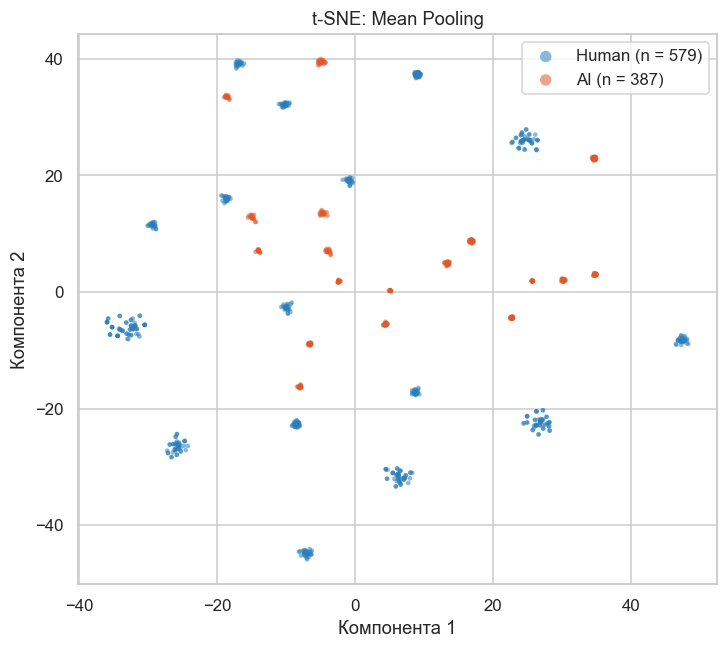

In [63]:
scatter_2d(emb_tsne[MP], y, 't-SNE: Mean Pooling')

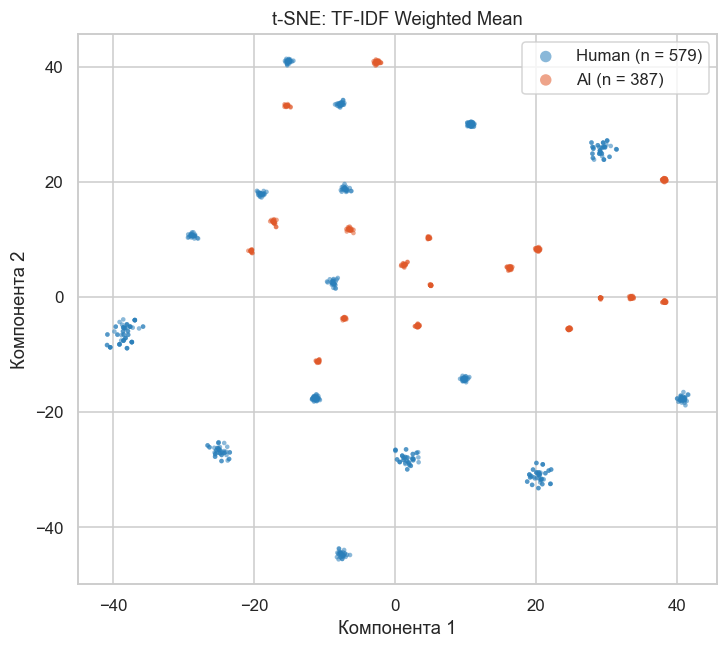

In [64]:
scatter_2d(emb_tsne[TW], y, 't-SNE: TF-IDF Weighted Mean')

### 6.2 Матриці плутанини

Матриці плутанини для кожного класифікатора (стовпці) і кожного методу агрегації (рядки), на тестовій вибірці з 194 документів (116 Human, 78 AI).

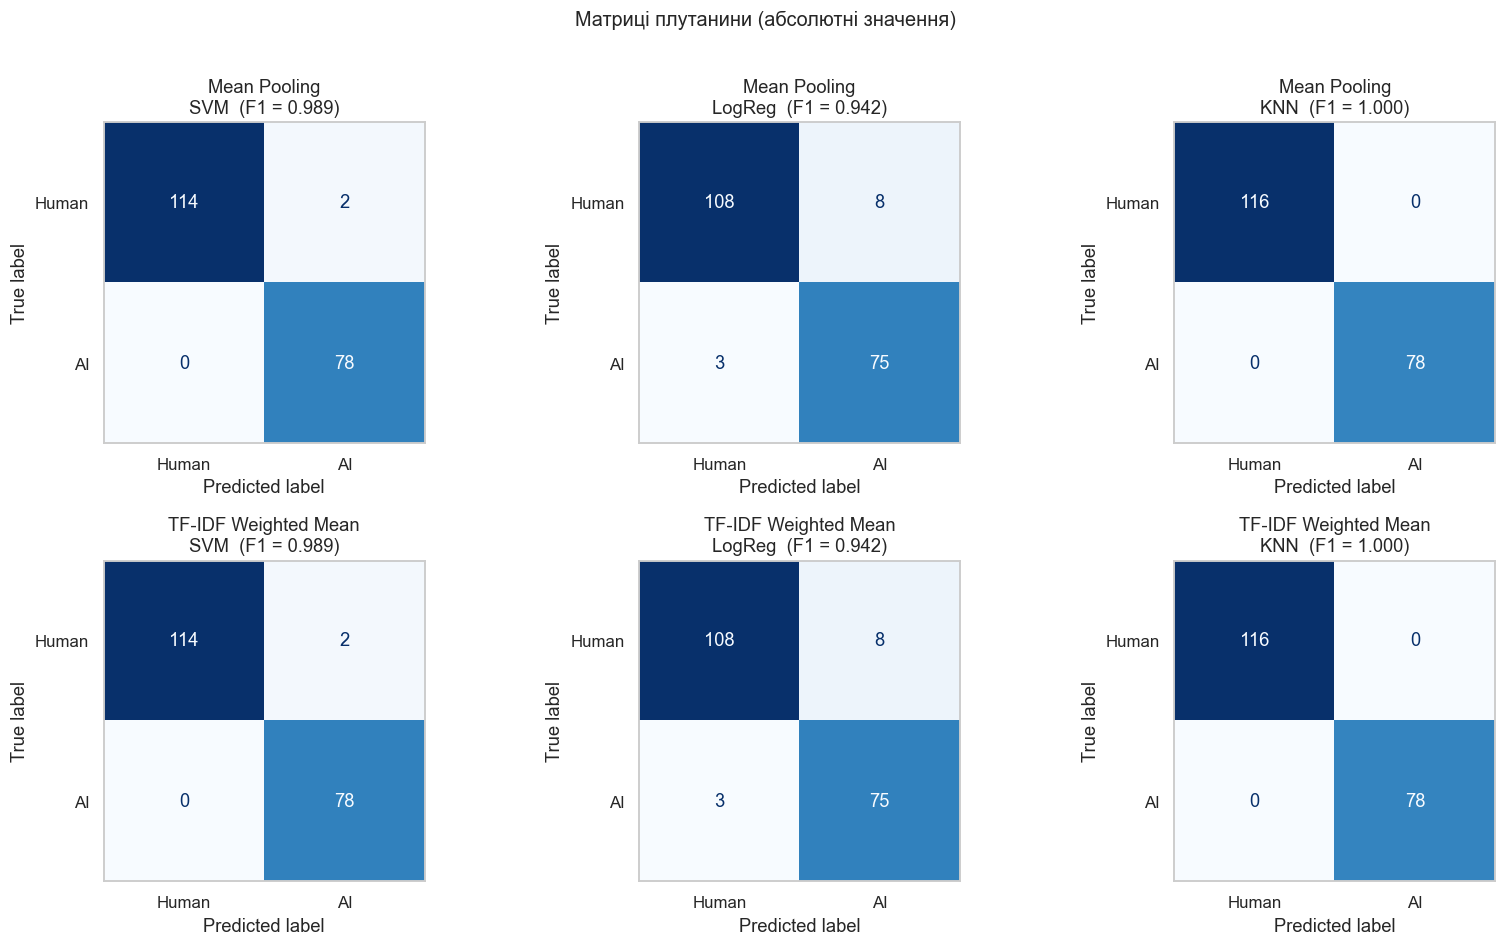

In [65]:
def plot_confusions(normalize=None):
    # Матриці плутанини: рядки — методи агрегації, стовпці — класифікатори.
    fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
    for i, agg in enumerate([MP, TW]):
        for j, c in enumerate(CLF_NAMES):
            ax = axes[i, j]
            ConfusionMatrixDisplay.from_predictions(
                y_test, store[(agg, c)], display_labels=['Human', 'AI'], normalize=normalize,
                cmap='Blues', colorbar=False, ax=ax, values_format='.2f' if normalize else 'd')
            ax.set_title(f'{agg}\n{c}  (F1 = {R.loc[(agg, c), "F1 (macro)"]:.3f})')
            ax.grid(False)
    kind = 'нормовані за істинним класом' if normalize else 'абсолютні значення'
    plt.suptitle(f'Матриці плутанини ({kind})', y=1.01, fontsize=13)
    plt.tight_layout()
    plt.show()


plot_confusions(normalize=None)

### Висновки до Етапу 6

* t-SNE. На обох графіках документи утворюють кілька десятків дуже щільних, добре відокремлених груп. Кожна група складається з документів одного класу: змішаних груп, де поряд були б Human- та AI-документи, на графіках немає. Проте класи не утворюють двох великих скупчень: кожен клас розпадається на багато дрібних груп, які на площині чергуються між собою. AI-групи здебільшого дуже компактні мікрокластери, серед Human-груп є й помітно розсіяніші.
* Графіки для Mean Pooling і TF-IDF Weighted Mean якісно однакові: така сама кількість груп, така сама їх чистота; відрізняється лише взаємне розташування груп, що для t-SNE є нормальним.
* Матриці плутанини. KNN не помиляється взагалі (116/0 та 0/78). SVM робить 2 помилки (2 Human-тексти визнано AI), логістична регресія — 11 помилок (8 Human-текстів визнано AI та 3 AI-тексти визнано Human). Для кожного класифікатора матриці в обох методах агрегації ідентичні.

---
## 5. Дослідницькі питання

Відповіді спираються на результати Етапів 5 і 6 (таблиці метрик, матриці плутанини, t-SNE) та на аналіз термінів у питанні 4.

### Питання 1. Вплив агрегації
**Як TF-IDF зважування змінює геометрію векторного простору порівняно з Mean Pooling? Чому це призводить (або не призводить) до покращення лінійної роздільності?**

Обидва документні вектори є опуклими комбінаціями векторів слів $v_d=\sum_i\alpha_i v_{w_i}$ ($\alpha_i\ge0$, $\sum_i\alpha_i=1$) і відрізняються лише вагами $\alpha_i$. При Mean Pooling $\alpha_i=1/m$, тому в середньому домінують слова, які трапляються найчастіше. Окрім того, у просторі skip-gram ембеддінгів вектори частотних слів мають спільну складову, через яку документні вектори групуються у вузькому конусі. При TF-IDF зважуванні внесок частих слів зменшується, а рідкісних — зростає, тому центр ваги документа зміщується від загальновживаної лексики до специфічної. У принципі це розтягує простір у напрямках рідкісних слів і полегшує лінійне відокремлення класів, які відрізняються саме такою лексикою. Але IDF не знає міток класів: підсилюються всі рідкісні слова, зокрема й випадкові, тому покращення не гарантоване.

На наших даних геометрія практично не змінилась. F1, Accuracy і Balanced Accuracy всіх трьох класифікаторів збігаються до четвертого знака, матриці плутанини ідентичні, а t-SNE-проєкції якісно однакові (те саме число компактних груп, та сама чистота). Єдине спостереження: ROC-AUC логістичної регресії зріс з 0,9813 до 0,9887 (+0,0074), тобто ранжування документів за ймовірністю дещо покращилось, але кількість помилок при порозі 0,5 не змінилась. Для лінійного класифікатора (Logistic Regression) F1 = 0,9416 в обох випадках, тож гіпотеза H₁ про кращу лінійну роздільність не підтвердилась.

Імовірні причини: 
1) Тексти дуже короткі (19–52 слова до обробки), тому в документі мало токенів і середнє слабко залежить від схеми ваг.
2) Корпус малий (словник 508 слів), вектори слів навчені на небагатьох контекстах і між собою схожі, тож будь-яка комбінація таких векторів потрапляє приблизно в те саме місце простору.
3) Класи й без зважування відокремлені на рівні груп схожих текстів (див. t-SNE), тому перерозподіл ваг між словами майже нічого не додає. Залишкові помилки логістичної регресії пов'язані не з вагами слів, а з лінійністю її межі: нелінійні SVM і KNN їх майже не роблять (див. питання 2).

### Питання 2. Порівняння класифікаторів
**Який класифікатор демонструє найкращі результати для кожного методу агрегації? Як це співвідноситься з природою даних (лінійна/нелінійна роздільність)?**

Для обох методів агрегації найкращим є KNN (F1 = 1,0000, помилок немає), далі SVM з RBF-ядром (F1 = 0,9893, 2 помилки) і найгіршою є логістична регресія (F1 = 0,9416, 11 помилок на 194 документи).

Логістична регресія будує лише лінійну роздільну межу; її слабший результат означає, що класи не розділяються однією гіперплощиною ідеально. SVM з RBF-ядром будує нелінійну межу й виправляє більшість помилок (з 11 до 2), отже в даних є помітна нелінійна складова. KNN — суто локальний метод, і він безпомилковий: це відповідає картині t-SNE, де кожен клас складається з багатьох щільних і чистих груп. Тобто структура даних — локальна та нелінійна: для тестового документа найближчі сусіди в навчальній вибірці майже завжди належать до того самого класу, бо серед них є дуже схожі документи тієї самої групи.

Тестова вибірка невелика: один документ відповідає приблизно 0,5 процентного пункту. А висока схожість документів усередині груп (більше половини датасету було точними дублікатами) може означати, що метрики на цьому датасеті оптимістичніші, ніж були б на різноманітніших текстах.

### Питання 3. Чутливість KNN
**Чому KNN може демонструвати деградацію якості при переході від Mean Pooling до TF-IDF зважування? Як це пов'язано з прокляттям розмірності та зміною метричних властивостей простору?**

KNN повністю залежить від метрики: він не вчить ваг ознак і не регуляризується, усі 100 координат однаково входять у евклідову відстань. У просторах високої розмірності відстані концентруються: різниця між відстанню до найближчого і до найдальшого сусіда стає малою порівняно з самою відстанню, тож найближчий сусід втрачає розрізняльну силу (прокляття розмірності). TF-IDF зважування змінює метричні властивості простору: збільшує вагу рідкісних слів, вектори яких навчені на малій кількості контекстів і тому зашумлені, змінює норми векторів та їх взаємне розташування. Відстані між документами тоді більше залежать від випадкових рідкісних слів, ніж від загальної ознаки класу, а сусіди можуть виявитися менш релевантними. Класифікатори з навчанням ваг (SVM, LogReg) здатні вимкнути шумові напрямки, KNN — ні, тому він чутливіший до такої зміни.

На наших даних деградації немає: KNN дає F1 = 1,0000 (і Accuracy, Balanced Accuracy, ROC-AUC = 1,0000) як для Mean Pooling, так і для TF-IDF Weighted Mean. Причини: (1) хоча формальна розмірність дорівнює 100, дані мають виражену кластерну структуру: документи всередині кожної групи набагато ближчі один до одного, ніж до решти, тому концентрація відстаней на пошук найближчих сусідів не впливає; (2) як показано в питанні 1, TF-IDF зважування на цих коротких текстах майже не змінює положення точок; (3) значення 1,0 — це верхня межа метрики, погіршитись KNN може лише при помітній зміні геометрії, а її не відбулось. Тобто описаний ефект можливий, але на цьому датасеті не підтвердився; його слід очікувати на більших і різноманітніших корпусах з великим словником, де схожих документів немає.

### Питання 4. Лінгвістична інтерпретація
**Які $n$-грами або слова мають найбільші TF-IDF значення для класу AI? Чи можна їх інтерпретувати як маркери штучного тексту?**

Для відповіді будується окрема TF-IDF-модель на уніграмах і біграмах лем (min_df=5, sublinear_tf=True). Для кожного терміна обчислюється середнє TF-IDF по документах кожного класу. Також обчислюється різниця $\Delta=\overline{\text{TF-IDF}}_{AI}-\overline{\text{TF-IDF}}_{Human}$: високий TF-IDF у класі AI ще не робить слово маркером, воно може бути так само характерним і для Human. Саме $\Delta$ показує відмінність між класами.

Розмір словника (уніграми + біграми, min_df=5): 1,135


,term,tfidf_AI,tfidf_Human,diff
0,challenge,0.0269,0.0153,0.0117
1,conversation,0.0242,0.0072,0.0170
2,think,0.0225,0.0000,0.0225
3,point,0.0213,0.0072,0.0141
4,expert,0.0201,0.0000,0.0201
5,framework,0.0201,0.0092,0.0109
6,development,0.0197,0.0000,0.0197
7,solution,0.0197,0.0000,0.0197
8,research,0.0193,0.0129,0.0064
9,underscore,0.0191,0.0000,0.0191


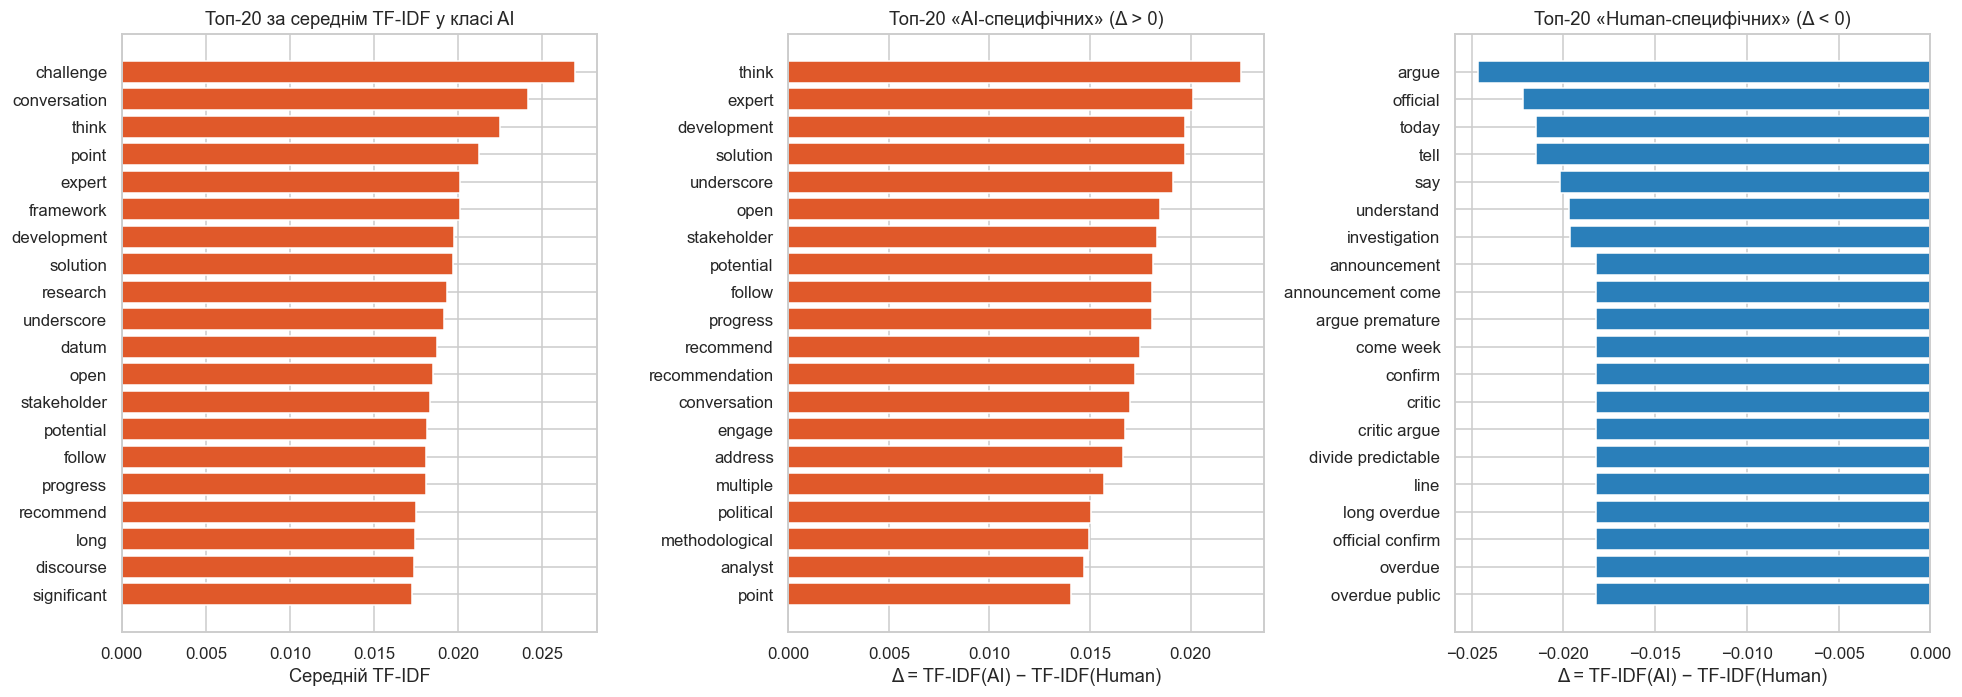

In [66]:
def uni_bigram_analyzer(tokens):
    # Уніграми + біграми сусідніх лем (після видалення стоп-слів).
    return tokens + [f'{a} {b}' for a, b in zip(tokens, tokens[1:])]


tfidf_ng = TfidfVectorizer(analyzer=uni_bigram_analyzer, min_df=5, sublinear_tf=True)
M = tfidf_ng.fit_transform(corpus).tocsr()
terms = np.asarray(tfidf_ng.get_feature_names_out())

ng_df = pd.DataFrame({
    'term': terms,
    'tfidf_AI': np.asarray(M[y == 1].mean(axis=0)).ravel(),
    'tfidf_Human': np.asarray(M[y == 0].mean(axis=0)).ravel(),
})
ng_df['diff'] = ng_df['tfidf_AI'] - ng_df['tfidf_Human']

top_ai      = ng_df.nlargest(20, 'tfidf_AI')       # найвищий середній TF-IDF у класі AI
top_diff_ai = ng_df.nlargest(20, 'diff')           # найбільш «AI-специфічні»
top_diff_hu = ng_df.nsmallest(20, 'diff')          # найбільш «Human-специфічні»

print(f'Розмір словника (уніграми + біграми, min_df=5): {len(terms):,}')
display(top_ai[['term', 'tfidf_AI', 'tfidf_Human', 'diff']].round(4).reset_index(drop=True))

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
panels = [(top_ai, 'tfidf_AI', 'Топ-20 за середнім TF-IDF у класі AI', PALETTE['AI']),
          (top_diff_ai, 'diff', 'Топ-20 «AI-специфічних» (Δ > 0)', PALETTE['AI']),
          (top_diff_hu, 'diff', 'Топ-20 «Human-специфічних» (Δ < 0)', PALETTE['Human'])]
for ax, (tbl, col, title, color) in zip(axes, panels):
    ax.barh(tbl['term'][::-1], tbl[col][::-1], color=color)
    ax.set_title(title)
    ax.set_xlabel('Середній TF-IDF' if col != 'diff' else 'Δ = TF-IDF(AI) − TF-IDF(Human)')
plt.tight_layout()
plt.show()

**Відповідь.**

* Найвищий середній TF-IDF у класі AI мають слова *challenge, conversation, think, point, expert, framework, development, solution, research, underscore, datum, open, stakeholder, potential, follow, progress, recommend, long, discourse, significant*.
* Найбільш AI-специфічні (найбільша різниця $\Delta$): *think, expert, development, solution, underscore, open, stakeholder, potential, follow, progress, recommend, recommendation, conversation, engage, address, multiple, political, methodological, analyst, point*. Для більшості з них (*think, expert, development, solution, underscore, open, stakeholder, potential, follow, progress, recommend*) середній TF-IDF у класі Human дорівнює нулю — у Human-текстах їх немає взагалі. Усі 20 найбільш AI-специфічних термінів — окремі слова.
* Найбільш Human-специфічні: *argue, official, today, tell, say, understand, investigation, announcement, confirm, critic, line, overdue* та біграми *announcement come, argue premature, come week, critic argue, divide predictable, long overdue, official confirm, overdue public* (8 із 20). Це характерні новинні штампи, що повторюються в різних текстах.
* Лексика класу AI — абстрактна, «консультативно-академічна» (*underscore, stakeholder, framework, methodological, discourse, engage, address, recommend*). Це узгоджується з гіпотезою про канцелярський стиль мовних моделей, а слово *underscore* взагалі часто називають улюбленим словом LLM. Тому такі слова можна розглядати як кандидатів у маркери штучного тексту.
* Високе значення TF-IDF саме по собі нічого не доводить: частина слів зі списку AI часто трапляється і в Human-текстах (*challenge* 0,027 проти 0,015, *research* 0,019 проти 0,013, *datum* 0,019 проти 0,013). Ознакою маркера є насамперед велике $\Delta$. TF-IDF не використовує міток, а датасет, імовірно, створений за шаблонами (колонка `generation_method` у перших рядках містить значення template+human_variation та style_simulation), тому різниця в лексиці може відображати відмінності шаблонів і тематики, а не справжній стиль. Класичні сполучники-маркери на кшталт *however, moreover* видаляються стоп-листом spaCy ще на етапі обробки й у цьому аналізі не представлені.

### Питання 5. Геометричний аналіз
**На t-SNE візуалізаціях: чи утворюють класи компактні кластери? Який метод агрегації забезпечує кращу кластеризацію?**

**Чи утворюють класи компактні кластери?** Так, але не у вигляді двох великих кластерів. На обох t-SNE-графіках видно кілька десятків дуже щільних груп, кожна з яких складається з документів одного класу, змішаних груп немає. Тобто кожен клас розпадається на багато дрібних компактних кластерів, які на площині розташовані впереміш з кластерами іншого класу. Імовірно, кожна група відповідає набору дуже схожих текстів (одна тема, один шаблон), що узгоджується з наявністю великої кількості точних дублікатів у вихідному датасеті. AI-кластери здебільшого щільніші (ізольовані мікрокластери), Human-кластери місцями більш розсіяні.

**Який метод кращий?** За картиною t-SNE жоден: для Mean Pooling і TF-IDF Weighted Mean кількість груп і їх чистота однакові, змінюється лише взаємне розташування груп, що для t-SNE є наслідком його стохастичної природи, а не ознакою кращої кластеризації. Це збігається з результатами класифікації, де матриці плутанини обох методів ідентичні. Слід враховувати, що t-SNE зберігає лише локальні сусідства, тому розмір кластерів і відстані між ними на графіку інтерпретувати кількісно не можна.

## Загальний висновок

У роботі побудовано повний пайплайн детекції текстів, згенерованих мовними моделями: очищення датасету та аналіз даних, обробка тексту в spaCy, навчання FastText (gensim), агрегація документних векторів двома способами (Mean Pooling та TF-IDF Weighted Mean) та класифікація трьома методами (SVM з RBF-ядром, Logistic Regression, KNN).

1. **Дані.** Датасет невеликий (2000 текстів довжиною 19–52 слова) і нерівний за класами (66,7 % Human, 33,3 % AI). Понад половину текстів (1034) виявилось точними дублікатами, їх видалено, залишилось 966 унікальних текстів. Саме видалення дублікатів було необхідним, щоб не допустити потрапляння копій одного тексту і в навчальну, і в тестову вибірку.
2. **Класифікація.** Усі три класифікатори добре розділяють класи: KNN — F1 = 1,000, SVM — 0,989, Logistic Regression — 0,942. Порядок однаковий для обох методів агрегації. Перевага нелінійних методів над лінійним означає, що класи не розділяються однією гіперплощиною і мають локальну, нелінійну структуру.
3. **Гіпотеза H₁ не підтвердилась.** TF-IDF зважування не покращило лінійну роздільність класів: F1, Accuracy та Balanced Accuracy всіх класифікаторів збіглися з Mean Pooling, матриці плутанини ідентичні, єдина зміна — ROC-AUC логістичної регресії (0,9813 → 0,9887). Імовірна причина — короткі тексти та малий корпус, на яких схема ваг майже не змінює середній вектор документа.
4. **Чутливість KNN.** Передбачена теорією деградація KNN при переході на TF-IDF (прокляття розмірності, зміна метрики) на цих даних не спостерігається: KNN залишається безпомилковим, бо дані мають виражену кластерну структуру.
5. **Геометрія.** За t-SNE обидва простори складаються з десятків щільних груп, кожна з яких належить одному класу; між двома методами агрегації якісної різниці немає.
6. **Лінгвістика.** Для класу AI характерна абстрактна «консультативно-академічна» лексика (*underscore, stakeholder, framework, recommend, engage, methodological*), для Human — новинні штампи й повторювані біграми (*long overdue, official confirm*). Ці слова можна розглядати як кандидатів у маркери штучного тексту, але з обережністю, оскільки датасет, імовірно, шаблонний.
7. **Загальне застереження.** Майже ідеальні метрики відображають радше легкість цього датасету (малий обсяг, шаблонні тексти, групи майже однакових документів), ніж здатність методу виявляти справжні тексти великих мовних моделей. Висновок про відсутність переваги TF-IDF зважування стосується саме цих даних; на довших і різноманітніших текстах ефект може бути іншим.